In [58]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/heartrate_seconds_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlyCalories_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlyIntensities_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/hourlySteps_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteCaloriesNarrow_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/minuteIntensitiesNarrow_merged.csv
/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16

## Ask

## Prepare

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
import pandas as pd

daily1 = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv')
daily2 = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv')
sleep = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/sleepDay_merged.csv')
weight1 = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/weightLogInfo_merged.csv')
weight2 = pd.read_csv('/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/weightLogInfo_merged.csv')

print(daily1.head())
print(daily2.head())
print(sleep.head())
print(weight1.head())
print(weight2.head())

           Id ActivityDate  TotalSteps  TotalDistance  TrackerDistance  \
0  1503960366    3/25/2016       11004           7.11             7.11   
1  1503960366    3/26/2016       17609          11.55            11.55   
2  1503960366    3/27/2016       12736           8.53             8.53   
3  1503960366    3/28/2016       13231           8.93             8.93   
4  1503960366    3/29/2016       12041           7.85             7.85   

   LoggedActivitiesDistance  VeryActiveDistance  ModeratelyActiveDistance  \
0                       0.0                2.57                      0.46   
1                       0.0                6.92                      0.73   
2                       0.0                4.66                      0.16   
3                       0.0                3.19                      0.79   
4                       0.0                2.16                      1.09   

   LightActiveDistance  SedentaryActiveDistance  VeryActiveMinutes  \
0                 4.07

## Process

In [61]:
# Merge daily activity & weight datasets & clean duplicates
daily_combined = pd.concat([daily1, daily2], ignore_index=True)
daily_combined = daily_combined.drop_duplicates(subset=['Id', 'ActivityDate'])

weight_combined = pd.concat([weight1, weight2], ignore_index=True)
weight_combined = weight_combined.drop_duplicates(subset=['Id', 'Date'])

# Clean sleep dataset duplicates
sleep = sleep.drop_duplicates(subset=['Id', 'SleepDay'])

print(daily_combined.info())
print(weight_combined.info())
print(sleep.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1373 entries, 0 to 1396
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        1373 non-null   int64  
 1   ActivityDate              1373 non-null   object 
 2   TotalSteps                1373 non-null   int64  
 3   TotalDistance             1373 non-null   float64
 4   TrackerDistance           1373 non-null   float64
 5   LoggedActivitiesDistance  1373 non-null   float64
 6   VeryActiveDistance        1373 non-null   float64
 7   ModeratelyActiveDistance  1373 non-null   float64
 8   LightActiveDistance       1373 non-null   float64
 9   SedentaryActiveDistance   1373 non-null   float64
 10  VeryActiveMinutes         1373 non-null   int64  
 11  FairlyActiveMinutes       1373 non-null   int64  
 12  LightlyActiveMinutes      1373 non-null   int64  
 13  SedentaryMinutes          1373 non-null   int64  
 14  Calories     

In [62]:
# Convert date columns to datetime format
daily_combined['ActivityDate'] = pd.to_datetime(daily_combined['ActivityDate'])
weight_combined['Date'] = pd.to_datetime(weight_combined['Date'], format='%m/%d/%Y %I:%M:%S %p')
sleep['SleepDay'] = pd.to_datetime(sleep['SleepDay'], format='%m/%d/%Y %I:%M:%S %p')

print(daily_combined.dtypes)
print(weight_combined.dtypes)
print(sleep.dtypes)

print(daily_combined.head())
print(weight_combined.head())
print(sleep.head())

Id                                   int64
ActivityDate                datetime64[ns]
TotalSteps                           int64
TotalDistance                      float64
TrackerDistance                    float64
LoggedActivitiesDistance           float64
VeryActiveDistance                 float64
ModeratelyActiveDistance           float64
LightActiveDistance                float64
SedentaryActiveDistance            float64
VeryActiveMinutes                    int64
FairlyActiveMinutes                  int64
LightlyActiveMinutes                 int64
SedentaryMinutes                     int64
Calories                             int64
dtype: object
Id                         int64
Date              datetime64[ns]
WeightKg                 float64
WeightPounds             float64
Fat                      float64
BMI                      float64
IsManualReport              bool
LogId                      int64
dtype: object
Id                             int64
SleepDay              date

In [63]:
# Check for missing values
print(daily_combined.isnull().sum())
print(weight_combined.isnull().sum())
print(sleep.isnull().sum())

Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64
Id                 0
Date               0
WeightKg           0
WeightPounds       0
Fat               94
BMI                0
IsManualReport     0
LogId              0
dtype: int64
Id                    0
SleepDay              0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64


count     4.000000
mean     19.750000
std       6.652067
min      10.000000
25%      19.000000
50%      22.000000
75%      22.750000
max      25.000000
Name: Fat, dtype: float64
Missing Fat values: 94


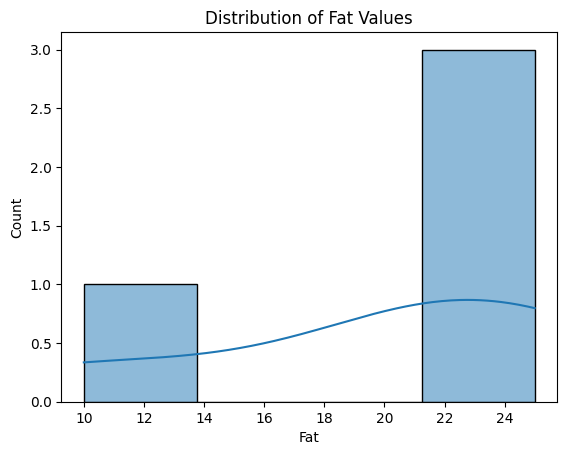

           Id                Date    WeightKg  WeightPounds  Fat        BMI  \
1  1927972279 2016-04-10 18:33:26  129.600006    285.719105  NaN  46.169998   
3  2873212765 2016-04-06 23:59:59   56.700001    125.002104  NaN  21.450001   
4  2873212765 2016-04-07 23:59:59   57.200001    126.104416  NaN  21.650000   
5  2891001357 2016-04-05 23:59:59   88.400002    194.888643  NaN  25.030001   
6  4445114986 2016-03-30 23:59:59   92.400002    203.707134  NaN  35.009998   

   IsManualReport          LogId  
1           False  1460313206000  
3            True  1459987199000  
4            True  1460073599000  
5            True  1459900799000  
6            True  1459382399000  
            Id                Date   WeightKg  WeightPounds   Fat        BMI  \
0   1503960366 2016-04-05 23:59:59  53.299999    117.506384  22.0  22.969999   
2   2347167796 2016-04-03 23:59:59  63.400002    139.773078  10.0  24.770000   
33  1503960366 2016-05-02 23:59:59  52.599998    115.963147  22.0  22.65000

In [64]:
# Summary statistics of Fat column (excluding missing)
print(weight_combined['Fat'].describe())

# Count missing values
missing_count = weight_combined['Fat'].isna().sum()
print(f"Missing Fat values: {missing_count}")

# Visualize distribution of Fat values
sns.histplot(weight_combined['Fat'], kde=True)
plt.title('Distribution of Fat Values')
plt.show()

# Check if missing values are random by comparing rows with and without missing Fat
print(weight_combined[weight_combined['Fat'].isna()].head())
print(weight_combined[weight_combined['Fat'].notna()].head())

In [65]:
# Remove rows where 'Fat' is missing values
weight_cleaned = weight_combined.dropna(subset=['Fat'])
print(weight_cleaned['Fat'].describe())

count     4.000000
mean     19.750000
std       6.652067
min      10.000000
25%      19.000000
50%      22.000000
75%      22.750000
max      25.000000
Name: Fat, dtype: float64


In [66]:
# Create new columns, convert minutes asleep to hours, extract day of week
sleep['TotalSleepHours'] = sleep['TotalMinutesAsleep'] / 60
daily_combined['DayOfWeek'] = daily_combined['ActivityDate'].dt.day_name()

print(sleep[['TotalMinutesAsleep', 'TotalSleepHours']].head())
print(daily_combined[['ActivityDate', 'DayOfWeek']].head())

   TotalMinutesAsleep  TotalSleepHours
0                 327         5.450000
1                 384         6.400000
2                 412         6.866667
3                 340         5.666667
4                 700        11.666667
  ActivityDate DayOfWeek
0   2016-03-25    Friday
1   2016-03-26  Saturday
2   2016-03-27    Sunday
3   2016-03-28    Monday
4   2016-03-29   Tuesday


In [67]:
# Convert column names to snake_case
daily_combined.rename(columns={
    'ActivityDate': 'activity_date',
    'TotalSteps': 'total_steps',
    'TotalDistance': 'total_distance',
    'TrackerDistance': 'tracker_distance',
    'LoggedActivitiesDistance': 'logged_activities_distance',
    'VeryActiveDistance': 'very_active_distance',
    'ModeratelyActiveDistance': 'moderately_active_distance',
    'LightActiveDistance': 'light_active_distance',
    'SedentaryActiveDistance': 'sedentary_active_distance',
    'VeryActiveMinutes': 'very_active_minutes',
    'FairlyActiveMinutes': 'fairly_active_minutes',
    'LightlyActiveMinutes': 'lightly_active_minutes',
    'SedentaryMinutes': 'sedentary_minutes',
    'DayOfWeek': 'day_of_week'
}, inplace=True)

weight_combined.rename(columns={
    'WeightKg': 'weight_kg',
    'IsManualReport': 'is_manual_report',
    'LogId': 'log_id'
}, inplace=True)

sleep.rename(columns={
    'SleepDay': 'sleep_day',
    'TotalSleepRecords': 'total_sleep_records',
    'TotalMinutesAsleep': 'total_minutes_asleep',
    'TotalTimeInBed': 'total_time_in_bed',
    'TotalSleepHours': 'total_sleep_hours'
}, inplace=True)

In [68]:
print(f"Unique users: {daily_combined['Id'].nunique()}")

Unique users: 35


In [69]:
# Explore numerical summaries
print(daily_combined['total_steps'].describe())
print(weight_combined['weight_kg'].describe())
print(sleep['total_sleep_hours'].describe())

count     1373.000000
mean      7247.360524
std       5214.783821
min          0.000000
25%       3108.000000
50%       6910.000000
75%      10538.000000
max      36019.000000
Name: total_steps, dtype: float64
count     98.000000
mean      72.466327
std       14.820618
min       52.599998
25%       61.500000
50%       62.500000
75%       85.250002
max      133.500000
Name: weight_kg, dtype: float64
count    410.000000
mean       6.986220
std        1.977265
min        0.966667
25%        6.016667
50%        7.208333
75%        8.166667
max       13.266667
Name: total_sleep_hours, dtype: float64


In [70]:
# Make activity level categories based on total steps
def activity_level(steps):
    if steps < 5000:
        return 'Low'
    elif steps < 10000:
        return 'Moderate'
    else:
        return 'High'

daily_combined['activity_level'] = daily_combined['total_steps'].apply(activity_level)

In [71]:
# Identify outliers
def find_outliers_iqr(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    return outliers, lower_bound, upper_bound

outliers_steps, lower_steps, upper_steps = find_outliers_iqr(daily_combined['total_steps'])
print(f"Total Steps Outliers:\n{outliers_steps}")
print(f"Lower bound: {lower_steps}, Upper bound: {upper_steps}\n")

outliers_sleep, lower_sleep, upper_sleep = find_outliers_iqr(sleep['total_sleep_hours'])
print(f"Total Sleep Hours Outliers:\n{outliers_sleep}")
print(f"Lower bound: {lower_sleep}, Upper bound: {upper_sleep}\n")

outliers_weight, lower_weight, upper_weight = find_outliers_iqr(weight_combined['weight_kg'])
print(f"Weight Kg Outliers:\n{outliers_weight}")
print(f"Lower bound: {lower_weight}, Upper bound: {upper_weight}\n")

filtered_steps_outliers = daily_combined[(daily_combined['total_steps'] < lower_steps) | (daily_combined['total_steps'] > upper_steps)]
print("Filtered Total Steps Outliers:")
print(filtered_steps_outliers)

filtered_sleep_outliers = sleep[(sleep['total_sleep_hours'] < lower_sleep) | (sleep['total_sleep_hours'] > upper_sleep)]
print("Filtered Total Sleep Hours Outliers:")
print(filtered_sleep_outliers)

filtered_weight_outliers = weight_combined[(weight_combined['weight_kg'] < lower_weight) | (weight_combined['weight_kg'] > upper_weight)]
print("Filtered Weight Kg Outliers:")
print(filtered_weight_outliers)

Total Steps Outliers:
391     25701
446     27572
450     24136
452     23014
454     28497
507     36019
708     22244
894     22770
1236    22359
1237    22988
1251    22026
1370    29326
1381    23629
1384    27745
1390    21727
Name: total_steps, dtype: int64
Lower bound: -8037.0, Upper bound: 21683.0

Total Sleep Hours Outliers:
4      11.666667
25      1.983333
26      2.066667
27     13.266667
28      2.283333
30     12.033333
32     12.500000
36      2.766667
65      1.016667
89      2.533333
110     1.283333
123     0.983333
125    11.533333
146     1.650000
150     1.366667
164     1.033333
172     1.633333
181     1.766667
195     2.100000
196     1.716667
198     1.916667
199     2.050000
246    12.916667
282     1.233333
337     1.316667
338     0.966667
365     1.233333
Name: total_sleep_hours, dtype: float64
Lower bound: 2.7916666666666674, Upper bound: 11.391666666666666

Weight Kg Outliers:
1     129.600006
35    133.500000
Name: weight_kg, dtype: float64
Lower bound: 

## Analyze

In [72]:
# Summary statistics
print(daily_combined.describe())
print(sleep.describe())
print(weight_combined.describe())

# Data types
print(daily_combined.dtypes)
print(sleep.dtypes)
print(weight_combined.dtypes)

                 Id                  activity_date   total_steps  \
count  1.373000e+03                           1373   1373.000000   
mean   4.782326e+09  2016-04-19 04:24:17.829570304   7247.360524   
min    1.503960e+09            2016-03-12 00:00:00      0.000000   
25%    2.320127e+09            2016-04-08 00:00:00   3108.000000   
50%    4.445115e+09            2016-04-19 00:00:00   6910.000000   
75%    6.962181e+09            2016-04-30 00:00:00  10538.000000   
max    8.877689e+09            2016-05-12 00:00:00  36019.000000   
std    2.381544e+09                            NaN   5214.783821   

       total_distance  tracker_distance  logged_activities_distance  \
count     1373.000000       1373.000000                 1373.000000   
mean         5.194137          5.167036                    0.128591   
min          0.000000          0.000000                    0.000000   
25%          2.140000          2.110000                    0.000000   
50%          4.900000          4

In [73]:
# Average steps per user
avg_steps_user = daily_combined.groupby('Id')['total_steps'].mean().reset_index().sort_values(by='total_steps', ascending=False)
print(avg_steps_user.head())

# Average steps by day of the week
avg_steps_day = daily_combined.groupby('day_of_week')['total_steps'].mean().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
print(avg_steps_day)

            Id   total_steps
34  8877689391  16263.333333
29  8053475328  14704.634146
0   1503960366  11910.755102
5   2022484408  11588.428571
27  7007744171  11550.297297
day_of_week
Monday       7541.319149
Tuesday      6830.850746
Wednesday    7547.575758
Thursday     7268.297436
Friday       7187.532663
Saturday     7752.271357
Sunday       6606.725389
Name: total_steps, dtype: float64


  activity_date  total_steps
0    2016-03-12       2771.5
1    2016-03-13       1613.0
2    2016-03-14       5728.0
3    2016-03-15       2953.0
4    2016-03-16       7311.0


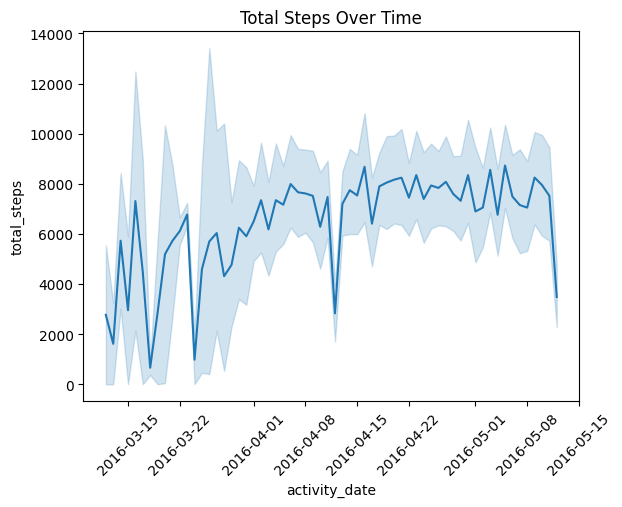

In [74]:
# Group by date and calculate average steps
steps_over_time = daily_combined.groupby('activity_date')['total_steps'].mean().reset_index()

print(steps_over_time.head())

# Line plot of total steps over time
sns.lineplot(x='activity_date', y='total_steps', data=daily_combined)
plt.title('Total Steps Over Time')
plt.xticks(rotation=45)
plt.show()

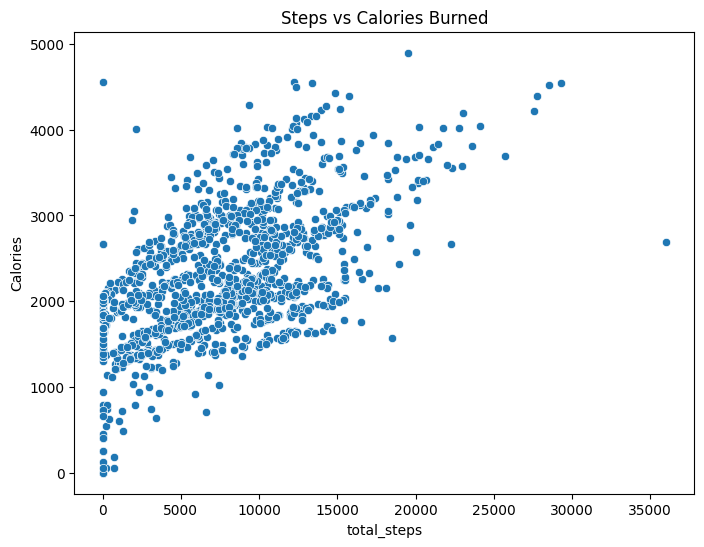

In [75]:
# Scatter plot of steps vs. calories
plt.figure(figsize=(8,6))
sns.scatterplot(data=daily_combined, x='total_steps', y='Calories')
plt.title('Steps vs Calories Burned')
plt.show()

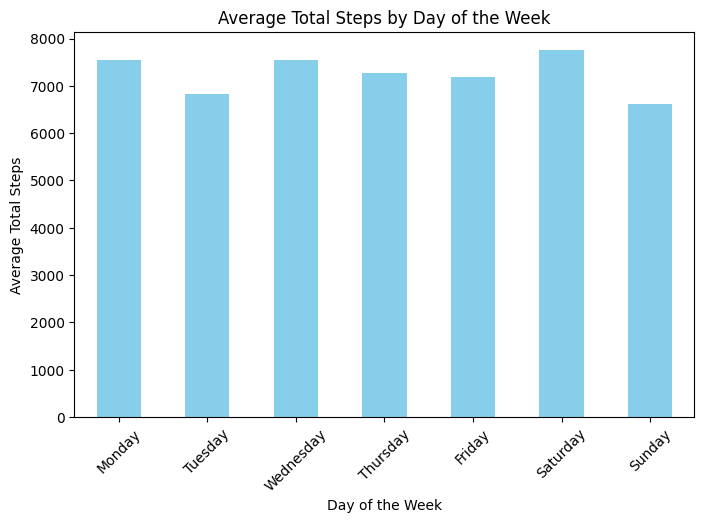

In [76]:
# Bar chart for average total steps by day of the week 
avg_steps_by_day = daily_combined.groupby('day_of_week')['total_steps'].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])

plt.figure(figsize=(8,5))
avg_steps_by_day.plot(kind='bar', color='skyblue')
plt.title('Average Total Steps by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Total Steps')
plt.xticks(rotation=45)
plt.show()

In [77]:
# How much time users spend inactive
daily_combined['sedentary_minutes_percent'] = (daily_combined['sedentary_minutes'] / (24*60)) * 100
print("Summary statistics for sedentary time percentage:")
print(daily_combined['sedentary_minutes_percent'].describe())

Summary statistics for sedentary time percentage:
count    1373.000000
mean       68.987922
std        21.860763
min         0.000000
25%        50.625000
50%        73.472222
75%        86.597222
max       100.000000
Name: sedentary_minutes_percent, dtype: float64


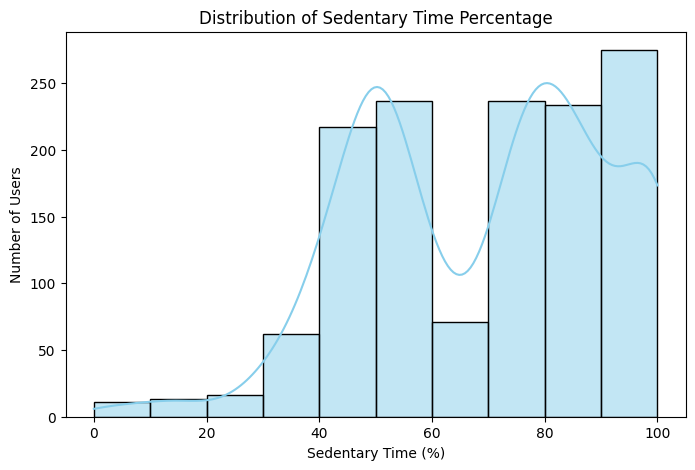

In [78]:
# Distribution of sedentary time percentages
plt.figure(figsize=(8, 5))
sns.histplot(daily_combined['sedentary_minutes_percent'], bins=10, kde=True, color='skyblue')
plt.title('Distribution of Sedentary Time Percentage')
plt.xlabel('Sedentary Time (%)')
plt.ylabel('Number of Users')
plt.show()

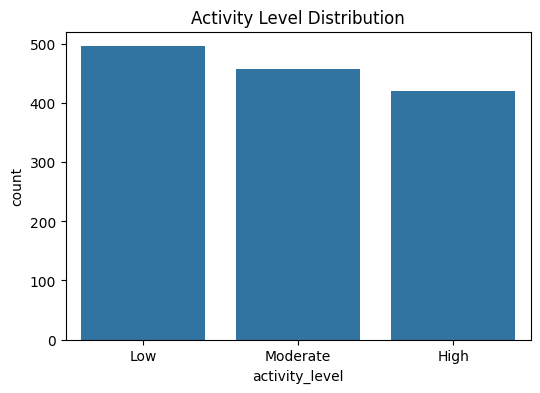

In [79]:
# Distribution of activity levels
plt.figure(figsize=(6,4))
sns.countplot(data=daily_combined, x='activity_level', order=['Low', 'Moderate', 'High'])
plt.title('Activity Level Distribution')
plt.show()

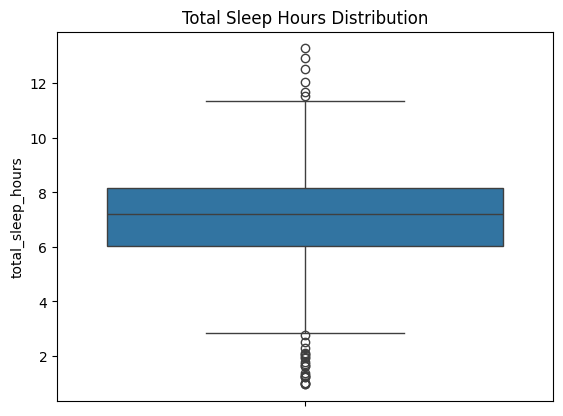

In [80]:
# Boxplot for sleep hours
sns.boxplot(y=sleep['total_sleep_hours'])
plt.title('Total Sleep Hours Distribution')
plt.show()

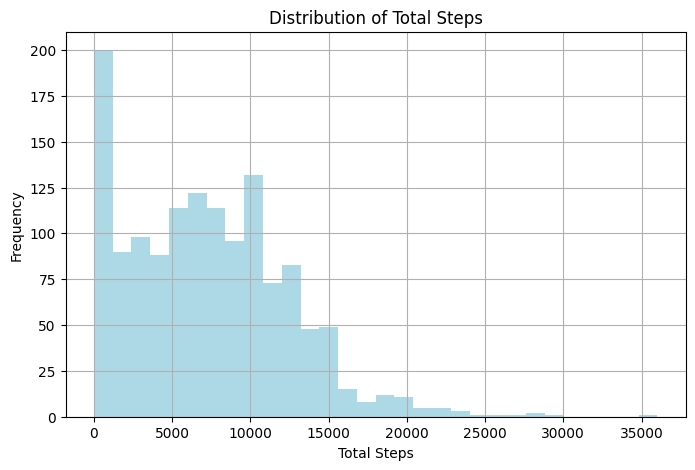

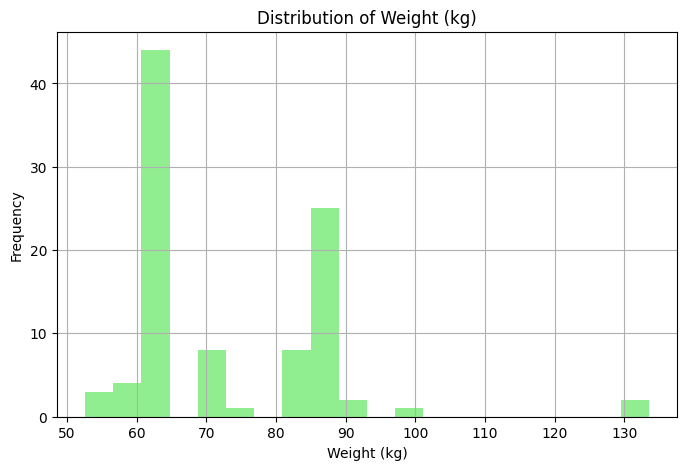

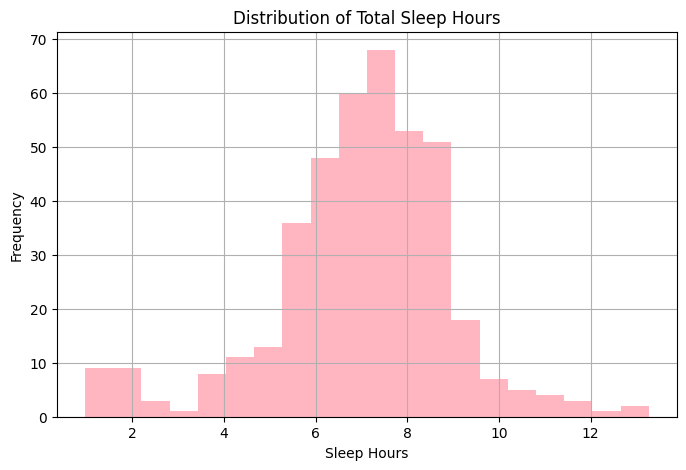

In [81]:
# Distribution with histograms
plt.figure(figsize=(8,5))
daily_combined['total_steps'].hist(bins=30, color='lightblue')
plt.title('Distribution of Total Steps')
plt.xlabel('Total Steps')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8,5))
weight_combined['weight_kg'].hist(bins=20, color='lightgreen')
plt.title('Distribution of Weight (kg)')
plt.xlabel('Weight (kg)')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8,5))
sleep['total_sleep_hours'].hist(bins=20, color='lightpink')
plt.title('Distribution of Total Sleep Hours')
plt.xlabel('Sleep Hours')
plt.ylabel('Frequency')
plt.show()

In [82]:
import numpy as np

# Align data by date
merged_data = daily_combined[['activity_date', 'total_steps']].merge(
    sleep[['sleep_day', 'total_sleep_hours']], left_on='activity_date', right_on='sleep_day', how='left'
).merge(
    weight_combined[['Date', 'weight_kg']], left_on='activity_date', right_on='Date', how='left'
)

correlation_matrix = merged_data[['total_steps', 'total_sleep_hours', 'weight_kg']].corr()
print(correlation_matrix)

                   total_steps  total_sleep_hours  weight_kg
total_steps           1.000000          -0.018766        NaN
total_sleep_hours    -0.018766           1.000000        NaN
weight_kg                  NaN                NaN        NaN


In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

# Non-outlier (clean) data for each variable
clean_steps = daily_combined[(daily_combined['total_steps'] >= lower_steps) & (daily_combined['total_steps'] <= upper_steps)]
clean_sleep = sleep[(sleep['total_sleep_hours'] >= lower_sleep) & (sleep['total_sleep_hours'] <= upper_sleep)]
clean_weight = weight_combined[(weight_combined['weight_kg'] >= lower_weight) & (weight_combined['weight_kg'] <= upper_weight)]

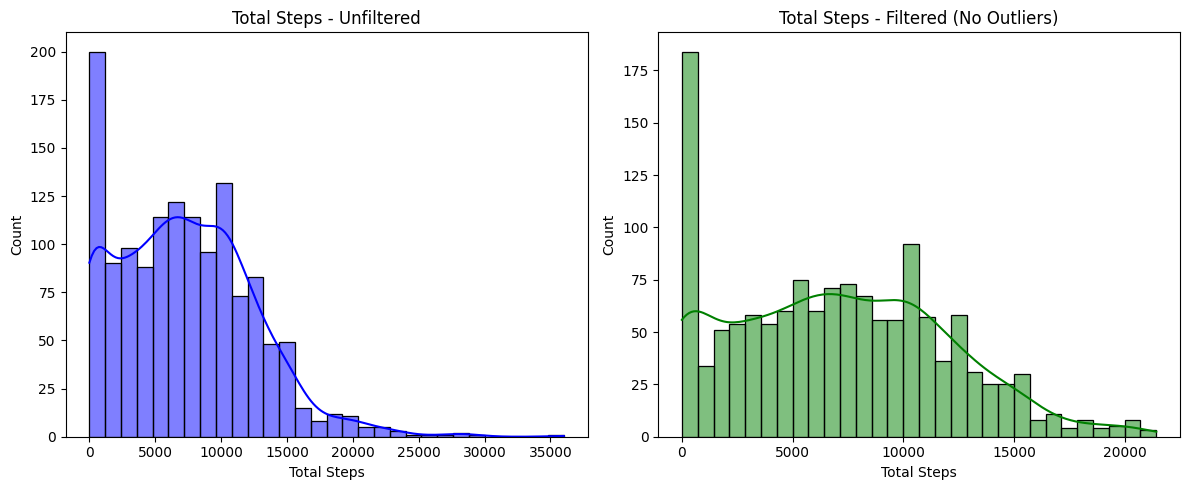

In [84]:
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
sns.histplot(daily_combined['total_steps'], bins=30, kde=True, color='blue')
plt.title('Total Steps - Unfiltered')
plt.xlabel('Total Steps')

plt.subplot(1, 2, 2)
sns.histplot(clean_steps['total_steps'], bins=30, kde=True, color='green')
plt.title('Total Steps - Filtered (No Outliers)')
plt.xlabel('Total Steps')

plt.tight_layout()
plt.show()

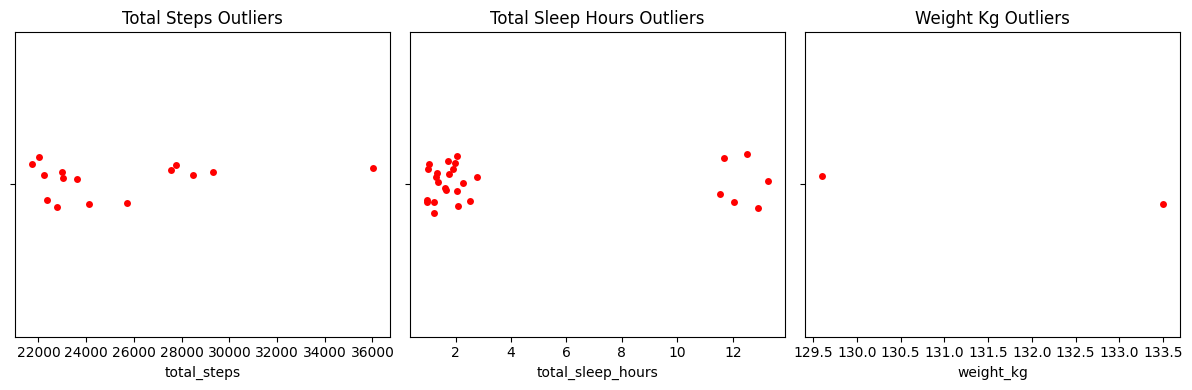

In [85]:
plt.figure(figsize=(12,4))

plt.subplot(1, 3, 1)
sns.stripplot(x=filtered_steps_outliers['total_steps'], color='red')
plt.title('Total Steps Outliers')

plt.subplot(1, 3, 2)
sns.stripplot(x=filtered_sleep_outliers['total_sleep_hours'], color='red')
plt.title('Total Sleep Hours Outliers')

plt.subplot(1, 3, 3)
sns.stripplot(x=filtered_weight_outliers['weight_kg'], color='red')
plt.title('Weight Kg Outliers')

plt.tight_layout()
plt.show()